# Financial Fidelity Evaluation Framework
### Synthetic Dow-10 financial time series from diffusion models

本 notebook 建立論文用的正式 Evaluation Tables。評估的**不是**「synthetic price 是否跟 real price 長得像」，
而是「synthetic financial market 是否保留真實市場的 statistical properties、temporal dynamics 與
cross-asset dependence structure」。

```
                    Financial Fidelity
                           │
              ┌────────────┴────────────┐
        Univariate                  Multivariate
       Stylized Facts              Cross-Asset
              │                         │
       5 Stylized Facts          3 Cross-Asset Metrics
              ↓                         ↓
       Stylized Score             Cross-Asset Score
              └────────────┬────────────┘
                           ↓
                  Overall Fidelity Score
```

所有邏輯放在 `evaluation/` package，本 notebook 只負責呼叫與呈現，
因此 notebook 與 `python -m evaluation.run_all` 的結果完全一致。
設計依據與取捨記錄見 [`evaluation_framework_design.md`](evaluation_framework_design.md)。

---
## 0. Existing Implementation Audit

在寫任何新程式之前，先盤點專案既有的 evaluation 程式碼：哪些可以沿用、哪些必須重寫、哪些有 bug。
**不修改任何原始生成程式碼**；發現的 bug 只列出並提出修正方案。

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50, "display.float_format", "{:.4f}".format)

from evaluation import config as C, loaders, pipeline, report, calibration as CAL
from evaluation import metrics_uni as MU, metrics_cross as MC
from evaluation import run_all as RA
from evaluation.pipeline import SF_METRICS, SF_LABELS

print("evaluation package loaded")

evaluation package loaded


In [2]:
audit = pd.DataFrame([
 ("Stylized facts 主函式", "generate_dow10.py:334 compute_stylized_facts (+4 份重複實作)",
  "可用但只有 lag-1，且 5 份彼此不一致", "Rewrite → evaluation/metrics_uni.py"),
 ("Hill tail index", "generate_dow10.py:305 (左尾) / eval_p0p1.py:19 (雙尾)",
  "BUG-2 兩份定義不同；BUG-3 q=0.95 使 k≈6", "Rewrite（左尾 + k-based 門檻）"),
 ("Jump", "generate_dow10.py:317 jump_measure (BNS RJ)",
  "BUG-1 max(0,·) 使所有 synthetic = 0", "Replace（保留未裁切值為診斷欄）"),
 ("Volatility clustering", "corrcoef(r[:-1]**2, r[1:]**2)，僅 lag 1",
  "BUG-6 單一 lag 無法代表衰減形狀", "Rewrite → ACF(r²) curve"),
 ("Leverage effect", "corrcoef(r[:-1], |r[1:]|)，僅 lag 1",
  "BUG-5 用 |r| 非 r²，且僅 lag 1", "Rewrite → Corr(r_t, r²_{t+k}) curve"),
 ("Skewness", "scipy.stats.skew (bias=True)", "可用，小樣本有偏誤", "Reuse（改 bias=False）"),
 ("Cross-asset correlation", "eval_p0p1.py:37 corr_mae", "正確（上三角、排除對角）", "Reuse"),
 ("Lower tail dependence", "eval_p0p1.py:42 lower_tail_dep",
  "BUG-4 real 與 syn 各自取分位數", "Rewrite（copula 版為主 + absolute 版為輔）"),
 ("PCA / eigenvalue spectrum", "不存在", "—", "New → metrics_cross.evr_spectrum"),
 ("Bootstrap / CI", "不存在", "—", "New → calibration.py"),
 ("資料載入", "eval_p0p1.py import 時 yf.download()", "BUG-7 不可重現、離線失敗", "Rewrite（改讀本地 CSV）"),
 ("模型輸出掃描", "不存在（硬寫 tag）", "—", "New → loaders.discover_models"),
], columns=["Component", "Existing Code", "Status", "Reuse / Rewrite"])
display(audit)

,Component,Existing Code,Status,Reuse / Rewrite
0,Stylized facts 主函式,generate_dow10.py:334 compute_stylized_facts (...,可用但只有 lag-1，且 5 份彼此不一致,Rewrite → evaluation/metrics_uni.py
1,Hill tail index,generate_dow10.py:305 (左尾) / eval_p0p1.py:19 (雙尾),BUG-2 兩份定義不同；BUG-3 q=0.95 使 k≈6,Rewrite（左尾 + k-based 門檻）
2,Jump,generate_dow10.py:317 jump_measure (BNS RJ),"BUG-1 max(0,·) 使所有 synthetic = 0",Replace（保留未裁切值為診斷欄）
3,Volatility clustering,"corrcoef(r[:-1]**2, r[1:]**2)，僅 lag 1",BUG-6 單一 lag 無法代表衰減形狀,Rewrite → ACF(r²) curve
4,Leverage effect,"corrcoef(r[:-1], |r[1:]|)，僅 lag 1",BUG-5 用 |r| 非 r²，且僅 lag 1,"Rewrite → Corr(r_t, r²_{t+k}) curve"
5,Skewness,scipy.stats.skew (bias=True),可用，小樣本有偏誤,Reuse（改 bias=False）
6,Cross-asset correlation,eval_p0p1.py:37 corr_mae,正確（上三角、排除對角）,Reuse
7,Lower tail dependence,eval_p0p1.py:42 lower_tail_dep,BUG-4 real 與 syn 各自取分位數,Rewrite（copula 版為主 + absolute 版為輔）
8,PCA / eigenvalue spectrum,不存在,—,New → metrics_cross.evr_spectrum
9,Bootstrap / CI,不存在,—,New → calibration.py


### 0.1 BUG-1 驗證：既有的 Jump 指標對 synthetic 完全沒有鑑別力

`RJ = max(0, (RV−BV)/RV)` 把所有 synthetic 的值裁切成 0。下面直接計算未裁切的原值以證明。

In [3]:
dates_p, R_p = loaders.load_real(C.PRIMARY_EVAL_START, C.PRIMARY_EVAL_END)
_models = loaders.select_models(loaders.discover_models(verbose=False), verbose=False)
_sd, _S = loaders.load_synthetic(_models[0], C.PRIMARY_EVAL_START, C.PRIMARY_EVAL_END)

bug1 = pd.DataFrame({
    "real RJ (raw)":      [MU.bns_relative_jump(R_p[:, i]) for i in range(10)],
    "real RJ (clipped)":  [MU.bns_relative_jump(R_p[:, i], clip=True) for i in range(10)],
    "syn RJ (raw)":       [MU.bns_relative_jump(_S[0, :, i]) for i in range(10)],
    "syn RJ (clipped)":   [MU.bns_relative_jump(_S[0, :, i], clip=True) for i in range(10)],
}, index=C.TICKERS)
display(bug1.round(4))
print(f"\nsynthetic 被 clip 成 0 的檔數: {(bug1['syn RJ (clipped)'] == 0).sum()}/10")
print("=> 既有 Jump 欄對每個 synthetic model 都會是 0，因此改用 threshold-based 定義。")

,real RJ (raw),real RJ (clipped),syn RJ (raw),syn RJ (clipped)
AAPL,0.0572,0.0572,-0.1464,0.0000
AMGN,0.0998,0.0998,-0.1409,0.0000
CRM,0.1188,0.1188,-0.1329,0.0000
CSCO,0.0474,0.0474,-0.1959,0.0000
IBM,0.1463,0.1463,-0.1247,0.0000
INTC,0.0877,0.0877,-0.1495,0.0000
MSFT,-0.0147,0.0000,-0.1373,0.0000
NKE,0.1785,0.1785,-0.1997,0.0000
VZ,0.0872,0.0872,-0.1022,0.0000
WMT,0.1102,0.1102,-0.1561,0.0000



synthetic 被 clip 成 0 的檔數: 10/10
=> 既有 Jump 欄對每個 synthetic model 都會是 0，因此改用 threshold-based 定義。


---
## 1. Research Objective

**評估對象**：多種 diffusion model 生成的 Dow-10 synthetic financial time series。

**評估問題**：synthetic market 是否保留真實市場的
1. **分布性質** — 尾部厚度決定極端損失機率；負偏度決定下檔風險的不對稱
2. **事件性質** — 跳躍的頻率與幅度決定 gap risk 與避險成本
3. **時序動態** — 波動聚集決定風險預測；leverage effect 決定波動率曲面的偏斜
4. **橫斷面結構** — 相關與共同因子決定分散化效果；尾部相依決定危機時的同時虧損

**刻意不使用**逐日 price trajectory correlation 作為 fidelity metric ——
在近乎不可預測的報酬序列上，它衡量的是預測能力而非模擬品質。

---
## 2. Configuration

Primary window 的選擇理由見 Section 4，且**在計算任何模型分數之前固定**。

In [4]:
print(f"PRIMARY_EVAL_START = {C.PRIMARY_EVAL_START}")
print(f"PRIMARY_EVAL_END   = {C.PRIMARY_EVAL_END}")
print(f"TICKERS ({C.N_TICKER}) = {C.TICKERS}")
print()
print("Robustness windows（不參與主要排名）:")
for k, v in C.ROBUSTNESS_WINDOWS.items():
    print(f"  {k:<14s} {v[0]} ~ {v[1]}")
print()
print(f"Hill k            = ceil(n_neg^{C.HILL_K_EXPONENT:.3f})")
print(f"Jump threshold    = q{C.JUMP_Q} of |r_real|  (由真實資料定義)")
print(f"ACF / LE max lag  = {C.ACF_MAX_LAG}   (< walk-forward PRED_LEN = {C.WALKFORWARD_PRED_LEN})")
print(f"Tail dep. level   = {C.TAIL_DEP_Q}")
print(f"Bootstrap         = stationary block, B={C.BOOTSTRAP_B}, seed={C.BOOTSTRAP_SEED}")
print(f"Score kernel      = {C.SCORE_KERNEL}   ->  Score = 2^(-D/tau)")
print(f"SF weighting      = {C.SF_WEIGHTING}  (distribution {C.W_DISTRIBUTION} / dynamics {C.W_DYNAMICS})")
print(f"Overall           = {C.W_SF} * SF + {C.W_CA} * CrossAsset")

PRIMARY_EVAL_START = 2018-01-02
PRIMARY_EVAL_END   = 2024-12-31
TICKERS (10) = ['AAPL', 'AMGN', 'CRM', 'CSCO', 'IBM', 'INTC', 'MSFT', 'NKE', 'VZ', 'WMT']

Robustness windows（不參與主要排名）:
  2020 Crisis    2020-01-01 ~ 2020-12-31
  2022 Bear      2022-01-01 ~ 2022-12-31

Hill k            = ceil(n_neg^0.667)
Jump threshold    = q0.95 of |r_real|  (由真實資料定義)
ACF / LE max lag  = 20   (< walk-forward PRED_LEN = 21)
Tail dep. level   = 0.05
Bootstrap         = stationary block, B=500, seed=20240816
Score kernel      = halving   ->  Score = 2^(-D/tau)
SF weighting      = hierarchical  (distribution 0.5 / dynamics 0.5)
Overall           = 0.5 * SF + 0.5 * CrossAsset


---
## 3. Data Discovery

自動掃描 `outputs/`，依檔案樣式把每個目錄分類成 protocol family。**模型清單不寫死**，
新增模型只需改 `evaluation/config.py` 的 `MODELS_WHITELIST`。

In [5]:
disc = loaders.discover_models()
ddf = pd.DataFrame([{k: v for k, v in m.items() if k != "files"} for m in disc])
print("\n各 protocol family 的日期涵蓋：")
display(ddf.groupby("protocol").agg(n=("tag", "size"), start=("start", "first"),
                                    end=("end", "first"), T=("T", "first")))
print("\n可進入 primary 主表的模型：")
display(ddf[ddf.eligible_for_primary][["tag", "protocol", "n_paths", "start", "end", "T"]])
print("\n被排除的原因（前 5 筆）：")
display(ddf[~ddf.eligible_for_primary][["tag", "protocol", "reason"]].head())

掃描 /mnt/kartd0030027/TimeDiff/outputs：找到 35 個候選目錄
  [walk_forward] 2 個
  [single_shot_2024] 32 個
  [other_universe] 1 個

各 protocol family 的日期涵蓋：


,n,start,end,T
protocol,,,,
other_universe,1,None,None,NaN
single_shot_2024,32,2024-01-02,2024-12-31,252.0000
walk_forward,2,2018-01-02,2024-12-31,1761.0000



可進入 primary 主表的模型：


,tag,protocol,n_paths,start,end,T
33,dow10_wf,walk_forward,1,2018-01-02,2024-12-31,1761.0000
34,dow10_wf_v2,walk_forward,50,2018-01-02,2024-12-31,1761.0000



被排除的原因（前 5 筆）：


,tag,protocol,reason
0,ablation_pred63,other_universe,"ticker universe 非 Dow 10（AAPL,AMZN,GOOGL,MSFT,..."
1,dow10_2024_flat,single_shot_2024,只有 2024 輸出，未涵蓋 primary window；需以 walk-forward ...
2,dow10_abl_base,single_shot_2024,只有 2024 輸出，未涵蓋 primary window；需以 walk-forward ...
3,dow10_abl_base_cal,single_shot_2024,只有 2024 輸出，未涵蓋 primary window；需以 walk-forward ...
4,dow10_abl_vol,single_shot_2024,只有 2024 輸出，未涵蓋 primary window；需以 walk-forward ...


> **關鍵限制**：32 個 `single_shot_2024` 配置只有 2024 的輸出，未涵蓋 primary window。
> 依 Option 1 的決定，它們必須以相同的 walk-forward rolling protocol 重新生成後才能進入主表 ——
> 這是生成端的工作，不在本 notebook 範圍。目前主表只有 baseline，
> fine-tuned 版本完成後加入 `MODELS_WHITELIST` 即可。

---
## 4. Time Window Selection

**選擇準則完全基於真實市場資料的統計性質**，在計算任何模型分數之前固定。
不因某個模型在某段期間表現較好而選擇該期間。

In [6]:
_, R_all = loaders.load_real("2015-01-01", "2024-12-31")
d_all, _ = loaders.load_real("2015-01-01", "2024-12-31")
Rdf = pd.DataFrame(R_all, index=d_all, columns=C.TICKERS)

rows = []
for y in range(2015, 2025):
    x = Rdf[Rdf.index.year == y]
    rows.append(dict(
        year=y, T=len(x), ann_vol=x.stack().std()*np.sqrt(252),
        ext3sig_pct=(x.abs() > 3*Rdf.std()).sum().sum()/x.size*100,
        VC_acf1=np.nanmean([np.corrcoef(x[t].values[:-1]**2, x[t].values[1:]**2)[0,1] for t in C.TICKERS]),
        LE_lag1=np.nanmean([np.corrcoef(x[t].values[:-1], x[t].values[1:]**2)[0,1] for t in C.TICKERS]),
        skew=np.nanmean([x[t].skew() for t in C.TICKERS])))
print("逐年市場環境（10 檔平均）")
display(pd.DataFrame(rows).set_index("year").round(4))

逐年市場環境（10 檔平均）


,T,ann_vol,ext3sig_pct,VC_acf1,LE_lag1,skew
year,,,,,,
2015,252,0.2457,0.9524,0.0779,-0.1002,0.1158
2016,252,0.2300,0.8333,0.0920,-0.0299,-0.3171
2017,251,0.1717,0.6773,0.0119,-0.0035,0.6514
2018,251,0.2766,1.4343,0.1032,-0.0653,-0.2550
2019,252,0.2196,0.6746,0.1290,-0.1025,-0.3477
2020,253,0.4228,5.4545,0.3776,-0.1034,0.0010
2021,252,0.2330,0.6349,0.0508,-0.0127,-0.4736
2022,251,0.3342,2.4303,0.0575,-0.0566,-0.2927
2023,250,0.2445,0.7200,0.0303,0.0056,-0.3864


In [7]:
CANDIDATES = {
    "A: 2024 only":     ("2024-01-01", "2024-12-31", "AI 行情 + 8 月 VIX 尖峰"),
    "B: 2020 COVID":    ("2020-01-01", "2020-12-31", "系統性危機"),
    "C: 2022 Bear":     ("2022-01-01", "2022-12-31", "升息熊市"),
    "D: 2018-2024":     ("2018-01-02", "2024-12-31", "平靜→危機→熊市→復甦，4 個 regime"),
    "E: 2021-2024":     ("2021-01-01", "2024-12-31", "危機後 + 熊市"),
}
rows = []
for name, (s, e, note) in CANDIDATES.items():
    _, X = loaders.load_real(s, e)
    n_neg = int(np.mean([(X[:, i] < 0).sum() for i in range(10)]))
    rows.append(dict(window=name, start=s, end=e, T=len(X),
                     ann_vol=X.std()*np.sqrt(252),
                     hill_alpha=np.nanmean([MU.hill_alpha(X[:, i]) for i in range(10)]),
                     hill_k=int(np.ceil(n_neg**C.HILL_K_EXPONENT)),
                     VC_curve=np.nanmean([np.nanmean(MU.acf_r2_curve(X[:, i])) for i in range(10)]),
                     LE_curve=np.nanmean([np.nanmean(MU.leverage_curve(X[:, i])) for i in range(10)]),
                     skew=np.nanmean([MU.skewness(X[:, i]) for i in range(10)]),
                     n_tail5=int(len(X)*0.05), note=note))
cand = pd.DataFrame(rows).set_index("window")
display(cand.round(4))

,start,end,T,ann_vol,hill_alpha,hill_k,VC_curve,LE_curve,skew,n_tail5,note
window,,,,,,,,,,,
A: 2024 only,2024-01-01,2024-12-31,252,0.2932,2.1740,24,-0.0080,-0.0010,-0.9597,12,AI 行情 + 8 月 VIX 尖峰
B: 2020 COVID,2020-01-01,2020-12-31,253,0.4227,2.0252,25,0.1345,-0.0596,0.0010,12,系統性危機
C: 2022 Bear,2022-01-01,2022-12-31,251,0.3341,2.5843,26,0.0037,-0.0048,-0.2927,12,升息熊市
D: 2018-2024,2018-01-02,2024-12-31,1761,0.2967,2.6102,89,0.0915,-0.0292,-0.4457,88,平靜→危機→熊市→復甦，4 個 regime
E: 2021-2024,2021-01-01,2024-12-31,1005,0.2794,2.6695,62,0.0206,-0.0103,-0.7450,50,危機後 + 熊市


### 4.1 決定性檢查：訊號是否高於估計噪音？

用 stationary block bootstrap 從**真實資料**抽兩組獨立樣本，計算兩組估計值之間的距離期望 `τ` ——
「即使模型完美，也必然存在的估計噪音尺度」。若真實訊號 `|θ_real|` 本身就小於 `τ`，
該 metric 在該 window 下**不具鑑別力**，用它評估模型在方法論上不成立。

In [8]:
rng = np.random.default_rng(C.BOOTSTRAP_SEED)
rows = []
for name in ["A: 2024 only", "B: 2020 COVID", "C: 2022 Bear", "D: 2018-2024"]:
    s, e, _ = CANDIDATES[name]
    _, X = loaders.load_real(s, e)
    rec = {"window": name, "T": len(X)}
    for lab, fn, dfn in [("skew", MU.skewness, MU.d_skewness),
                         ("VC", MU.acf_r2_curve, MU.d_curve_l1),
                         ("LE", MU.leverage_curve, MU.d_curve_l1)]:
        taus, sigs = [], []
        for i in range(10):
            t = CAL.tau_univariate(X[:, i], fn, dfn, B=150, rng=rng)
            v = fn(X[:, i]); v = np.nanmean(v) if np.ndim(v) else v
            taus.append(t); sigs.append(abs(v))
        rec[f"tau_{lab}"] = np.nanmean(taus)
        rec[f"|signal|_{lab}"] = np.nanmean(sigs)
        rec[f"SNR_{lab}"] = np.nanmean(sigs)/np.nanmean(taus)
    rows.append(rec)
snr_tbl = pd.DataFrame(rows).set_index("window")
display(snr_tbl.round(4))
print("\nSNR < 1 = 真實訊號淹沒在自身估計噪音裡 -> 該 window 無法支撐該 metric")

,T,tau_skew,|signal|_skew,SNR_skew,tau_VC,|signal|_VC,SNR_VC,tau_LE,|signal|_LE,SNR_LE
window,,,,,,,,,,
A: 2024 only,252,1.2349,1.4721,1.1921,0.0466,0.0094,0.2024,0.0645,0.0081,0.1258
B: 2020 COVID,253,0.6488,0.5217,0.8041,0.0782,0.1345,1.7187,0.0728,0.0596,0.8179
C: 2022 Bear,251,0.5985,0.5896,0.9850,0.0586,0.0086,0.1471,0.0697,0.0103,0.1472
D: 2018-2024,1761,0.5203,0.5033,0.9672,0.0453,0.0915,2.0182,0.0323,0.0292,0.9026



SNR < 1 = 真實訊號淹沒在自身估計噪音裡 -> 該 window 無法支撐該 metric


### 4.2 候選 window 評估與最終選擇

| Window | 市場背景 | 代表性 | 資料長度 | Extreme events | 適合 SF evaluation？ |
|---|---|---|---|---|---|
| **A 2024** | AI 行情 + 8 月 VIX 尖峰 | 單一 regime | T=252 | 3σ 事件 1.39% | **否** — skewness 的 τ 大於訊號本身；VC 曲線平均 ≈ −0.008、LE ≈ −0.001，該年幾乎不存在波動聚集 |
| **B 2020 COVID** | 系統性危機 | 危機 regime 的最佳樣本 | T=253 | 3σ 事件 2.09%、VC 0.378 | 作為 robustness 佳，作為主 window 會過度偏向危機情境 |
| **C 2022 Bear** | 升息熊市 | 熊市 regime | T=251 | 3σ 事件 1.39% | 同 A 的小樣本問題；VC 訊號亦弱 |
| **D 2018–2024** | 平靜 → 危機 → 熊市 → 復甦 | **4 個 regime 全涵蓋** | **T=1,761** | 3σ 事件 1.61%、尾部曝險 88 筆 | **是** — 五個 fact 的訊號皆高於噪音 |
| **E 2021–2024** | 危機後 | 缺 COVID 這個唯一的系統性危機樣本 | T=1,005 | 3σ 事件 1.26% | 可行但 regime 代表性弱於 D |

**PRIMARY EVALUATION WINDOW = D：2018-01-02 ~ 2024-12-31**

1. 唯一同時具備足夠訊號與足夠樣本的 window（見 4.1）
2. regime 代表性最完整：2018 修正、2020 COVID、2022 熊市、2023–24 復甦
3. 估計可靠度：Hill 尾部樣本 k 由 6 → 42（相對 SE 40% → 15%）；5% 尾部曝險 12 → 88 筆
4. 10 檔於該期間零缺值
5. 等於 walk-forward 的生成期，不需截斷、不引入未來資料

**Anti-cherry-picking**：以上理由全部只使用真實市場資料的統計性質，未使用任何模型的 fidelity 分數，
且刻意排除「某模型在該期間表現較好」這一類理由。所有 Method 使用同一 window。
2020 / 2022 僅作 **regime robustness analysis**，不與 primary 混在一起決定排名。

---
## 5. Data Alignment

檢查 §25 的公平性要求：日期對齊、ticker 對齊、無未來資料、只用生成期、
價格串接不接真實價。

In [9]:
checks = []
for wname, (ws, we) in C.EVAL_WINDOWS.items():
    rd, R = loaders.load_real(ws, we)
    for m in _models:
        sd, S = loaders.load_synthetic(m, ws, we, real_dates=rd)
        ok = loaders.assert_alignment(rd, sd, R, S, m["tag"])
        checks.append(dict(window=wname, model=m["display"], T_real=len(rd), T_syn=len(sd),
                           paths=S.shape[0], first=str(rd[0].date()), last=str(rd[-1].date()),
                           aligned=ok))
display(pd.DataFrame(checks))

,window,model,T_real,T_syn,paths,first,last,aligned
0,2018-2024 (Primary),Baseline (TimeDiff walk-forward),1761,1761,50,2018-01-02,2024-12-31,True
1,2020 Crisis,Baseline (TimeDiff walk-forward),253,253,50,2020-01-02,2020-12-31,True
2,2022 Bear,Baseline (TimeDiff walk-forward),251,251,50,2022-01-03,2022-12-30,True


### 5.1 生成協定的公平性檢查（人工核對 `walk_forward_dow10.py`）

| 檢查項 | 結果 | 依據 |
|---|---|---|
| condition 只用過去真實資料 | ✓ | block j 的 cond = `real[origin+21j−63 : origin+21j]` |
| 使用未來資料 | ✓ 無 | 同上 |
| 價格串接方式 | ✓ | `reconstruct_ohlc` 由 2017 最後一日的真實 Close **單一 seed 全段累積**，區塊與重訓邊界都不重置 —— 生成第 t 日的價格接生成第 t−1 日，不接真實價 |
| evaluation 只用生成期 | ✓ | 2018-01-02 起皆為生成輸出 |
| ticker 對齊 | ✓ | 同一 `TICKERS` 順序 |

> **必須在論文中揭露的限制**：synthetic 序列**不是 free-running simulation** ——
> 每 21 個交易日就被重新錨定到一段真實的 63 日 condition。
> 因此 **lag ≥ 21 的時間相依性有一部分來自真實 condition 而非模型本身**，
> 這正是把 VC / LE 的 lag 上限設為 `K = 20 < PRED_LEN = 21` 的直接原因。
> 本評估也因此**不能**推論模型的長期自主模擬能力。

---
## 6. Stylized Facts Definitions

五個 fact 屬於**三種不同的數學性質**，因此**不可**全部使用 `|synthetic − real|`：

| 層級 | Fact | Raw metric | Distance | 為何是這個 distance |
|---|---|---|---|---|
| Distribution | Heavy Tail | 左尾 Hill $\hat\alpha$ | $\lvert\log(\alpha_{syn}/\alpha_{real})\rvert$ | $\alpha$ 是正的尺度參數；log-ratio 對「高估 2 倍」與「低估 2 倍」給相同距離，相對誤差會偏袒低估 |
| Distribution | Negative Skewness | $g_1$ | $\lvert s_{syn}-s_{real}\rvert$ | skewness 無量綱且可跨零，相對距離無定義 |
| Event | Jump | $(f, m)$ @ 真實門檻 | $\lvert\Delta f\rvert$ 與 $\lvert\log(m_{syn}/m_{real})\rvert$ | 比例用差；幅度是正的尺度參數用 log-ratio |
| Temporal | Vol. Clustering | $\rho(k)=\mathrm{Corr}(r_t^2, r_{t+k}^2)$ | $\frac1K\sum_k\lvert\Delta\rho(k)\rvert$ | 是一條曲線，須同時比較水平與衰減形狀 |
| Temporal | Leverage | $L(k)=\mathrm{Corr}(r_t, r_{t+k}^2)$ | $\frac1K\sum_k\lvert\Delta L(k)\rvert$ | 同上 |

### 6.1 Heavy Tail — Hill estimator

$$P(X > x)\sim x^{-\alpha},\qquad
\hat\alpha=\Big[\tfrac1k\sum_{j=1}^{k}\log\tfrac{X_{(j)}}{X_{(k)}}\Big]^{-1},\qquad
k=\lceil n_{neg}^{2/3}\rceil$$

$X$ = 由大到小排序的 $\{-r: r<0\}$。$\alpha$ 小 ⇒ 尾巴厚。
只用負報酬，因為下跌尾部才是金融風險關心的對象。
既有實作用固定分位數 `q=0.95`，在 $T=252$ 時 $k\approx6$（相對 SE 40%）；改用 k-based 門檻後 $k\approx42$。

### 6.2 Jump — 門檻**必須**由真實資料定義

$$u_i=q_{0.95}(\lvert r^{real}_i\rvert),\qquad
f_i=\frac{\#\{t:\lvert r_{t,i}\rvert>u_i\}}{T},\qquad
m_i=\mathbb E\big[\lvert r_{t,i}\rvert \,\big|\, \lvert r_{t,i}\rvert>u_i\big]$$

synthetic **一律套用真實資料的 $u_i$**，避免 circular evaluation。
無超越事件時 magnitude 記為 undefined 且該子分數 = 0，**不得靜默丟棄**。
門檻取 q95 而非 q99 純粹依**曝險數**決定（q99 在 T=1761 下每檔僅 18 筆，q95 為 88 筆）。

### 6.3 為什麼 $K=20$

1. 約一個交易月，是波動聚集在實務上最相關的水平
2. Bartlett SE $\approx 1/\sqrt T$；更長的 lag 已落在噪音帶內
3. **walk-forward 的 `PRED_LEN = 21`** —— lag $\ge 21$ 的相依性有一部分來自真實 condition
   而非模型，納入會系統性高估模型

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for i, t in enumerate(["AAPL", "MSFT"]):
    j = C.TICKERS.index(t)
    k = np.arange(1, C.ACF_MAX_LAG+1)
    axes[0].plot(k, MU.acf_r2_curve(R_p[:, j]), "-o", ms=5, lw=2,
                 color=report.SERIES[i], label=f"{t} real")
    axes[1].plot(k, MU.leverage_curve(R_p[:, j]), "-o", ms=5, lw=2,
                 color=report.SERIES[i], label=f"{t} real")
axes[0].set_title("Volatility clustering: ACF(r²)", loc="left", fontweight="bold")
axes[1].set_title("Leverage effect: Corr(r_t, r²_{t+k})", loc="left", fontweight="bold")
for ax in axes:
    ax.axhline(0, color=report.INK_MUTED, lw=0.8)
    ax.set_xlabel("lag k"); ax.grid(axis="y", alpha=0.9); ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, labelcolor=report.INK_SECONDARY)
plt.tight_layout(); plt.show()

---
## 7. Stylized Facts Raw Metrics  <span style="color:#8a8983">(STEP 1)</span>

真實資料的 raw metrics（逐檔），附 bootstrap / subsampling 95% CI。

In [11]:
real_ci = RA.table_real_ci(R_p, dates_p, C.PRIMARY_WINDOW_KEY)
display(real_ci[["ticker", "hill_alpha", "hill_lo", "hill_hi",
                 "skew", "skew_lo", "skew_hi"]].round(4))
display(real_ci[["ticker", "vc_mean", "vc_lo", "vc_hi", "le_mean", "le_lo", "le_hi",
                 "jump_thr", "jump_freq", "jump_n", "jump_mag"]].round(4))

,ticker,hill_alpha,hill_lo,hill_hi,skew,skew_lo,skew_hi
0,AAPL,2.9055,2.6642,3.3614,-0.2161,-0.5307,0.1465
1,AMGN,2.6244,2.6285,2.9721,0.2881,-0.3140,0.8203
2,CRM,2.7769,2.5736,3.1366,-0.2110,-1.4593,1.0380
3,CSCO,2.3535,2.0900,2.6524,-0.7997,-1.8511,-0.0112
4,IBM,2.0108,1.6856,2.2110,-0.7485,-1.4122,0.1065
5,INTC,2.2428,2.0699,2.4746,-1.3685,-2.7273,-0.1675
6,MSFT,3.2178,3.2387,3.8106,-0.2665,-0.6085,0.1303
7,NKE,2.4925,2.2990,2.7764,-0.7306,-2.1981,0.6650
8,VZ,2.6623,2.4204,3.0719,-0.0696,-0.6336,0.4504
9,WMT,2.8150,2.8278,3.1924,-0.3341,-1.7319,0.8249


,ticker,vc_mean,vc_lo,vc_hi,le_mean,le_lo,le_hi,jump_thr,jump_freq,jump_n,jump_mag
0,AAPL,0.1502,0.0149,0.1373,-0.0480,-0.0480,-0.0031,0.0381,0.0500,88,0.0552
1,AMGN,0.1179,0.0007,0.1396,-0.0208,-0.0360,0.0096,0.0307,0.0500,88,0.0476
2,CRM,0.0343,0.0011,0.0639,-0.0161,-0.0308,0.0058,0.0438,0.0500,88,0.0684
3,CSCO,0.1099,0.0025,0.1357,-0.0447,-0.0534,0.0046,0.0321,0.0500,88,0.0508
4,IBM,0.1251,-0.0007,0.1304,-0.0452,-0.0582,0.0095,0.0315,0.0500,88,0.0498
5,INTC,0.0420,-0.0006,0.0795,-0.0171,-0.0292,0.0098,0.0481,0.0500,88,0.0760
6,MSFT,0.1634,0.0163,0.1480,-0.0417,-0.0443,0.0018,0.0364,0.0500,88,0.0519
7,NKE,0.0330,-0.0039,0.0756,-0.0240,-0.0391,0.0030,0.0377,0.0500,88,0.0611
8,VZ,0.0703,0.0049,0.0976,-0.0182,-0.0276,0.0035,0.0261,0.0500,88,0.0384
9,WMT,0.0692,0.0014,0.0922,-0.0161,-0.0245,0.0051,0.0235,0.0500,88,0.0410


執行完整 pipeline（三個 window × 所有模型）。這一步會重新校準 τ 並評估所有路徑。

In [12]:
results, models, tau_cache = RA.run_all_windows(B=C.BOOTSTRAP_B)
W = C.PRIMARY_WINDOW_KEY
print(f"\n完成：{len(results)} 組 (model, window)")

掃描 /mnt/kartd0030027/TimeDiff/outputs：找到 35 個候選目錄
  [walk_forward] 2 個
  [single_shot_2024] 32 個
  [other_universe] 1 個
選入評估的模型：['Baseline (TimeDiff walk-forward)']

=== Window 2018-2024 (Primary)  2018-01-02~2024-12-31  T=1761 ===
  校準 tau（stationary block bootstrap，只用真實資料）...
  tau 完成 (54s)
  [dow10_wf_v2 @ 2018-2024 (Primary)] T=1761, paths=50

=== Window 2020 Crisis  2020-01-01~2020-12-31  T=253 ===
  校準 tau（stationary block bootstrap，只用真實資料）...
  tau 完成 (26s)
  [dow10_wf_v2 @ 2020 Crisis] T=253, paths=50

=== Window 2022 Bear  2022-01-01~2022-12-31  T=251 ===
  校準 tau（stationary block bootstrap，只用真實資料）...
  tau 完成 (25s)
  [dow10_wf_v2 @ 2022 Bear] T=251, paths=50

完成：3 組 (model, window)


---
## 8. Stylized Facts Distances  <span style="color:#8a8983">(STEP 2)</span>

每個 metric 用**自己的** distance；raw distance 與 score 分開呈現，絕不混在同一張表。

In [13]:
res_p = {mdl: r for (mdl, w), r in results.items() if w == W}
for mdl, r in res_p.items():
    print(f"### {mdl} — raw distance（10 檔平均，跨路徑平均）")
    d = r["asset"].groupby("metric")[["distance"]].agg(["mean", "std", "min", "max"])
    d.index = [SF_LABELS[i] for i in d.index]
    display(d.round(4))

### Baseline (TimeDiff walk-forward) — raw distance（10 檔平均，跨路徑平均）


distance                      
                            mean    std    min     max
Heavy Tail (Hill alpha)   0.4076 0.1708 0.0007  0.7973
Jump Behaviour            0.0498 0.0009 0.0420  0.0500
Leverage Effect           0.1504 0.0815 0.0257  0.3096
Negative Skewness         1.0323 2.9011 0.0006 20.7166
Volatility Clustering     0.1349 0.0743 0.0315  0.3085

---
## 9. Stylized Facts Scores  <span style="color:#8a8983">(STEP 3 + 4)</span>

### Normalization：以「真實資料自身的重抽噪音」為尺度

$$\tau_m=\mathbb E_b\Big[D_m\big(\hat\theta(X^{(b_1)}_{real}),\ \hat\theta(X^{(b_2)}_{real})\big)\Big],
\qquad \boxed{\ \text{Score}_m = 2^{-D_m/\tau_m}\ }$$

* $D=0 \Rightarrow \text{Score}=1$（完全一致）
* $D=\tau \Rightarrow \text{Score}=0.5$（誤差恰等於真實估計量自身的重抽誤差）
* $\tau$ **只用真實資料**計算，不接觸任何 synthetic 輸出 ⇒ 無 circularity

**為什麼不用其他做法**

| 方法 | 問題 |
|---|---|
| $1-D$ | 需要 $D\in[0,1]$，只有 TV distance 滿足 |
| $e^{-D}$ | 等於把 $\tau$ 任意設為 $1/\ln 2$，無依據 |
| $D/\lvert\theta_{real}\rvert$ | leverage effect 真實值僅 −0.03、jump frequency 0.05 ⇒ **近零分母**（§23）。本框架除以**標準誤**而非 metric 值，因此近零不構成問題 |

In [14]:
tau_uni, tau_cross = tau_cache[W]
tau_tbl = pd.DataFrame(tau_uni).T
tau_tbl.loc["MEAN"] = tau_tbl.mean()
print("τ（每檔，由真實資料的 stationary block bootstrap 得出）")
display(tau_tbl.round(5))
print("\nτ（cross-asset）")
display(pd.Series(tau_cross).round(5).to_frame("tau"))

τ（每檔，由真實資料的 stationary block bootstrap 得出）


,heavy_tail,skewness,jump_freq,jump_mag,vol_clustering,leverage
AAPL,0.1158,0.2232,0.0073,0.0688,0.0546,0.0337
AMGN,0.1279,0.2987,0.0073,0.0621,0.0593,0.0345
CRM,0.1196,0.7771,0.0073,0.0540,0.0269,0.0282
CSCO,0.1359,0.5482,0.0073,0.0712,0.0530,0.0342
IBM,0.1245,0.4240,0.0073,0.0618,0.0544,0.0384
INTC,0.1133,0.8073,0.0073,0.0616,0.0355,0.0286
MSFT,0.1462,0.2286,0.0073,0.0768,0.0577,0.0346
NKE,0.1248,0.8428,0.0073,0.0653,0.0329,0.0276
VZ,0.1004,0.3265,0.0073,0.0457,0.0418,0.0308
WMT,0.1829,0.7408,0.0073,0.0755,0.0425,0.0328



τ（cross-asset）


,tau
correlation,0.0656
pca,0.0550
tail_dep_copula,0.0601
tail_dep_absolute,0.0678


In [15]:
print("訊噪比 |θ_real| / τ  —— < 1 代表該 window 下統計功效不足")
snr = RA.table_snr(results, W)
display(snr.round(3))
low = [k for k, v in res_p[list(res_p)[0]]["snr"].items() if v < C.MIN_SIGNAL_TO_NOISE]
print(f"\nPrimary window 下統計功效不足的 metric: {[SF_LABELS[m] for m in low] or '無'}")

訊噪比 |θ_real| / τ  —— < 1 代表該 window 下統計功效不足


,Heavy Tail (Hill alpha),Negative Skewness,Jump Behaviour,Volatility Clustering,Leverage Effect
2018-2024 (Primary),20.5990,0.9820,6.8050,1.8710,0.8830
2020 Crisis,8.9130,0.9160,2.6180,1.6770,0.8130
2022 Bear,11.8850,0.8290,2.6180,0.1430,0.1480



Primary window 下統計功效不足的 metric: ['Negative Skewness', 'Leverage Effect']


### Kernel 敏感度：排名不應依賴 score 轉換的函數形式

In [16]:
rows = []
for mdl, r in res_p.items():
    for kern in C.SCORE_KERNEL_SENSITIVITY:
        a = pipeline.evaluate_paths_univariate(r["real"],
                loaders.load_synthetic([m for m in models if m["display"] == mdl][0],
                                       C.PRIMARY_EVAL_START, C.PRIMARY_EVAL_END)[1],
                r["real_metrics"], r["tau_uni"], kernel=kern)
        sf = pipeline.aggregate_sf(a).mean(axis=0)
        rows.append(dict(Method=mdl, kernel=kern,
                         **{SF_LABELS[m]: sf[m] for m in SF_METRICS}, SF_Score=sf["SF_Score"]))
display(pd.DataFrame(rows).round(4))

,Method,kernel,Heavy Tail (Hill alpha),Negative Skewness,Jump Behaviour,Volatility Clustering,Leverage Effect,SF_Score
0,Baseline (TimeDiff walk-forward),halving,0.1770,0.5997,0.0062,0.2170,0.1161,0.2507
1,Baseline (TimeDiff walk-forward),gaussian,0.1380,0.6476,0.0019,0.1948,0.0754,0.2417


---
## 10. Cross-Asset Metrics

| Metric | 量的是什麼 | 為何需要它 |
|---|---|---|
| **Correlation** | 線性共動的**水平**（逐元素） | 決定分散化效果 |
| **PCA / EVR** | 共同潛在因子**結構**（譜） | 檢查 synthetic market 是否保留市場因子；**不是用來預測** |
| **Tail dependence** | **極端**共動（copula） | 危機時同時虧損的機率，VaR/CVaR 的關鍵輸入 |

### 10.1 PCA 用相關矩陣還是共變異矩陣？→ **相關矩陣**

1. 共變異矩陣的特徵值會被**變異數尺度差異**主導。多數模型 VolRatio 僅 0.2–0.6，
   用共變異等於把已在 univariate 層評過的尺度誤差**重複計分**，扭曲 Overall Score
2. 金融 RMT / 因子結構文獻（Laloux et al. 1999；Plerou et al. 2002）的標準做法即為相關矩陣

$$\mathrm{EVR}_k=\frac{\lambda_k}{\sum_j\lambda_j},\qquad
D_{PCA}=\tfrac12\sum_k\lvert \mathrm{EVR}^{real}_k-\mathrm{EVR}^{syn}_k\rvert$$

用 **total variation distance** 而非單純 mean absolute difference：EVR 是機率向量（和為 1），
$\frac12 L_1$ 正是 TV distance，天然有界於 $[0,1]$ 且有明確機率意義。

### 10.2 Tail dependence 為何用 copula 版為主

$$\lambda_L(i,j)=P\big(U_j<u \mid U_i<u\big),\qquad U=F(X),\ u=0.05$$

* $\lambda_L$ 依定義是 **copula 泛函**，對邊際的單調變換不變 —— 使用各序列自身的經驗 CDF
  不是「挑對自己有利的門檻」，而是該量的標準定義（Joe 1997；McNeil et al. 2015）
* 邊際尺度誤差已在 univariate 層懲罰過，用真實絕對門檻會**重複計分**
* 變異數收縮嚴重的模型在真實絕對門檻下曝險數為 0 ⇒ 條件機率 undefined

**absolute-threshold 版完整保留為 supplementary analysis**（表格中的 `[suppl.]` 欄）。

---
## 11. Cross-Asset Distances

In [17]:
cad = RA.table_ca_distances(results, W)
display(cad.round(4))
print("\n注意 [suppl.] 欄：absolute-threshold 版的 synthetic 曝險數遠低於真實值，")
print("這正是它不能作為主指標的原因 —— 但它本身是一個有意義的發現（見 Section 20）。")

,Corr MAE,PCA Distance (TV),Tail Dep. Distance (copula),Corr MAE (Spearman),[suppl.] Tail Dep. Distance (absolute),avg #exceed < real q05 (real),avg #exceed < real q05 (syn)
Baseline (TimeDiff walk-forward),0.0787,0.0704,0.1441,0.0482,0.4818,88.0000,0.3160



注意 [suppl.] 欄：absolute-threshold 版的 synthetic 曝險數遠低於真實值，
這正是它不能作為主指標的原因 —— 但它本身是一個有意義的發現（見 Section 20）。


---
## 12. Cross-Asset Scores

In [18]:
cas = RA.table_ca_scores(results, W)
display(cas.round(4))

print("\n冗餘性檢查（事先設定的規則，不依結果調整）：")
red = RA.redundancy_check(results, W)
print(f"  n = {red['n']}, corr(Score_corr, Score_pca) = {red['corr']}")
print(f"  -> {red['verdict']}")

,Corr Score,PCA Score,Tail Dep. Score (copula),Cross-Asset Score,[suppl.] Tail Dep. Score (absolute)
Baseline (TimeDiff walk-forward),0.4757,0.4530,0.1932,0.3740,0.0074



冗餘性檢查（事先設定的規則，不依結果調整）：
  n = 50, corr(Score_corr, Score_pca) = 0.999363693460001
  -> 重複資訊 -> 依事先規則改為 corr+pca 合計 0.5、tail dep 0.5


---
## 13. Composite Scores  <span style="color:#8a8983">(STEP 5 + 6 + 7)</span>

### Stylized Facts 權重：hierarchical

$$\text{Distribution}=\tfrac12(S_{HT}+S_{Skew}),\qquad
\text{Dynamics}=\tfrac13(S_{Jump}+S_{VC}+S_{LE})$$
$$\text{SF Score}=0.5\cdot\text{Distribution}+0.5\cdot\text{Dynamics}$$

**為什麼不是等權**：等權方案下 Dynamics 會拿到 60% 的總權重，
但該 60/40 純粹來自「我們碰巧定義了 3 個 dynamics 與 2 個 distribution 指標」——
是**指標數量的產物，不是金融意義的判斷**。Hierarchical 讓權重反映兩個概念軸的對等地位，
且未來新增指標時保持穩定。**權重在看到任何模型分數之前固定。**

### Cross-Asset 與 Overall

$$\text{CrossAsset}=\tfrac13(S_{corr}+S_{PCA}+S_{tailDep}),\qquad
\text{Overall}=0.5\cdot\text{SF}+0.5\cdot\text{CrossAsset}$$

Overall 採 50/50 且未偏離：univariate 與 multivariate fidelity 是兩個**互補且不可互相取代**的品質軸 ——
邊際分布完美但股票間互相獨立的生成器，與相關結構完美但邊際是高斯的生成器，
作為 synthetic market 都同樣不可用。

In [19]:
rows = []
for mdl, r in res_p.items():
    for wt in ["hierarchical", "equal"]:
        sf = pipeline.aggregate_sf(r["asset"], weighting=wt).mean(axis=0)
        rows.append(dict(Method=mdl, weighting=wt,
                         Distribution=sf["Distribution"], Dynamics=sf["Dynamics"],
                         SF_Score=sf["SF_Score"]))
wcmp = pd.DataFrame(rows)
display(wcmp.round(4))
print("附錄用：equal weighting 的結果一併報告，以證明結論不依賴權重選擇。")

,Method,weighting,Distribution,Dynamics,SF_Score
0,Baseline (TimeDiff walk-forward),hierarchical,0.3884,0.1131,0.2507
1,Baseline (TimeDiff walk-forward),equal,0.3884,0.1131,0.2232


附錄用：equal weighting 的結果一併報告，以證明結論不依賴權重選擇。


---
## 14. TABLE SF-1 — 10-stock averaged normalized scores

每一格 ∈ [0,1]，1 = 最接近 Real。

In [20]:
sf1 = RA.table_sf1(results, W)
display(sf1.round(4))
sf1.to_csv(os.path.join(C.TABLE_DIR, "table_SF1_scores.csv"))

,Heavy Tail (Hill alpha),Negative Skewness,Jump Behaviour,Volatility Clustering,Leverage Effect,SF Score
Baseline (TimeDiff walk-forward),0.1770,0.5997,0.0062,0.2170,0.1161,0.2507


---
## 15. TABLE SF-2 — Raw Metric / Distance Table

**這張表不放 score**，目的是讓 reviewer 看到 score 背後的實際誤差。距離越低越好。

In [21]:
sf2 = RA.table_sf2(results, W)
display(sf2.round(4))
sf2.to_csv(os.path.join(C.TABLE_DIR, "table_SF2_distances.csv"))

,Heavy Tail (Hill alpha) D,Negative Skewness D,Jump Behaviour D,Volatility Clustering D,Leverage Effect D,Jump D(freq),Jump D(mag)
Baseline (TimeDiff walk-forward),0.4076,1.0323,0.0498,0.1349,0.1504,0.0498,0.8982


---
## 16. TABLE SF-3 — Asset-level robustness / dispersion

回答「模型平均很好，是不是只是被某幾支股票拉高？」

In [22]:
sf3 = RA.table_sf3(results, W)
display(sf3.round(4))
sf3.to_csv(os.path.join(C.TABLE_DIR, "table_SF3_dispersion.csv"), index=False)

,Method,Metric,Mean,Std,Min,Max,Min ticker,Max ticker
0,Baseline (TimeDiff walk-forward),Heavy Tail (Hill alpha),0.1770,0.1818,0.0359,0.5719,INTC,WMT
1,Baseline (TimeDiff walk-forward),Negative Skewness,0.5997,0.2555,0.2684,0.9190,INTC,CRM
2,Baseline (TimeDiff walk-forward),Jump Behaviour,0.0062,0.0034,0.0045,0.0130,VZ,CRM
3,Baseline (TimeDiff walk-forward),Volatility Clustering,0.2170,0.1991,0.0100,0.5776,NKE,AAPL
4,Baseline (TimeDiff walk-forward),Leverage Effect,0.1161,0.1421,0.0049,0.4138,NKE,CRM


---
## 17. Cross-Asset Tables

Score 越高越好；Raw distance 越低越好。兩者分開呈現。

In [23]:
print("Cross-asset scores")
display(cas.round(4))
print("Cross-asset raw distances")
display(cad.round(4))
cas.to_csv(os.path.join(C.TABLE_DIR, "table_crossasset_scores.csv"))
cad.to_csv(os.path.join(C.TABLE_DIR, "table_crossasset_distances.csv"))

Cross-asset scores


,Corr Score,PCA Score,Tail Dep. Score (copula),Cross-Asset Score,[suppl.] Tail Dep. Score (absolute)
Baseline (TimeDiff walk-forward),0.4757,0.4530,0.1932,0.3740,0.0074


Cross-asset raw distances


,Corr MAE,PCA Distance (TV),Tail Dep. Distance (copula),Corr MAE (Spearman),[suppl.] Tail Dep. Distance (absolute),avg #exceed < real q05 (real),avg #exceed < real q05 (syn)
Baseline (TimeDiff walk-forward),0.0787,0.0704,0.1441,0.0482,0.4818,88.0000,0.3160


---
## 18. Overall Model Comparison

**2018–2024 = Primary Evaluation（唯一決定排名的 window）**
2020 / 2022 僅作 regime robustness analysis，不與 primary 混在一起決定排名。

In [24]:
ov = RA.table_overall(results)
display(ov.round(4))
ov.to_csv(os.path.join(C.TABLE_DIR, "table_overall_comparison.csv"), index=False)

,Method,Time,T,Paths,Stylized Facts,Cross-Asset,Overall,Role,Low-power metrics
0,Baseline (TimeDiff walk-forward),2018-2024 (Primary),1761,50,0.2507,0.3740,0.3124,PRIMARY (ranking),"Negative Skewness, Leverage Effect"
1,Baseline (TimeDiff walk-forward),2020 Crisis,253,50,0.3644,0.5441,0.4543,robustness only,"Negative Skewness, Leverage Effect"
2,Baseline (TimeDiff walk-forward),2022 Bear,251,50,0.3367,0.1609,0.2488,robustness only,"Negative Skewness, Volatility Clustering, Leve..."


---
## 19. Robustness / Dispersion Analysis

三個面向：跨股票離散度、跨生成路徑離散度（**生成不確定性**，與估計不確定性不同）、
以及 regime 穩健性。

In [25]:
print("跨生成路徑的離散度（生成不確定性）")
for mdl, r in res_p.items():
    d = r["sf"][["SF_Score"]].join(r["ca"][["CA_Score"]])
    d["Overall"] = C.W_SF*d.SF_Score + C.W_CA*d.CA_Score
    print(f"\n{mdl}  (n_paths = {r['n_paths']})")
    display(d.agg(["mean", "std", "min", "max"]).round(4))

跨生成路徑的離散度（生成不確定性）

Baseline (TimeDiff walk-forward)  (n_paths = 50)


,SF_Score,CA_Score,Overall
mean,0.2507,0.3740,0.3124
std,0.0217,0.0504,0.0351
min,0.1223,0.1344,0.1363
max,0.2793,0.4534,0.3602


In [26]:
print("Hill k 的敏感度（尾部門檻選擇是否影響結論）")
rows = []
for mult in C.HILL_K_SENSITIVITY:
    a_r = [MU.hill_alpha(R_p[:, i], k_mult=mult) for i in range(10)]
    a_s = [np.mean([MU.hill_alpha(_S[p, :, i], k_mult=mult) for p in range(_S.shape[0])])
           for i in range(10)]
    rows.append(dict(k_multiplier=mult, alpha_real=np.nanmean(a_r), alpha_syn=np.nanmean(a_s),
                     D=np.nanmean([abs(np.log(s/r)) for s, r in zip(a_s, a_r)])))
display(pd.DataFrame(rows).round(4))

Hill k 的敏感度（尾部門檻選擇是否影響結論）


,k_multiplier,alpha_real,alpha_syn,D
0,0.5000,2.7845,4.9673,0.5874
1,1.0000,2.6102,3.8616,0.3948
2,2.0000,2.0661,2.8520,0.3207


In [27]:
print("Jump 門檻的敏感度（q95 vs q99）")
rows = []
for q in C.JUMP_Q_SENSITIVITY:
    fr, fs, nr, ns = [], [], [], []
    for i in range(10):
        u = MU.jump_threshold(R_p[:, i], q=q)
        f0, _, n0 = MU.jump_freq_mag(R_p[:, i], u)
        f1 = np.mean([MU.jump_freq_mag(_S[p, :, i], u)[0] for p in range(_S.shape[0])])
        n1 = np.mean([MU.jump_freq_mag(_S[p, :, i], u)[2] for p in range(_S.shape[0])])
        fr.append(f0); fs.append(f1); nr.append(n0); ns.append(n1)
    rows.append(dict(q=q, freq_real=np.mean(fr), freq_syn=np.mean(fs),
                     n_exceed_real=np.mean(nr), n_exceed_syn=np.mean(ns)))
display(pd.DataFrame(rows).round(5))
print("\n門檻的選擇只依曝險數決定，不依結果決定。")

Jump 門檻的敏感度（q95 vs q99）


,q,freq_real,freq_syn,n_exceed_real,n_exceed_syn
0,0.9500,0.0500,0.0002,88.0000,0.3160
1,0.9900,0.0102,0.0001,18.0000,0.2360



門檻的選擇只依曝險數決定，不依結果決定。


---
## Figures

每張圖同時輸出 `results/figures/*.png` 與 `results/figure_data/*.txt`
（txt 內含產生該圖所用的完整數值，不只是圖片說明）。

In [28]:
made = RA.make_figures(results, W)
for png, txt in made:
    print(os.path.basename(png), "+", os.path.basename(txt))

stylized_scores.png + stylized_scores.txt
cross_asset_scores.png + cross_asset_scores.txt
pca_spectrum.png + pca_spectrum.txt
correlation_matrix_Baseline.png + correlation_matrix_Baseline.txt
tail_dependence_Baseline.png + tail_dependence_Baseline.txt
overall_comparison.png + overall_comparison.txt
asset_level_scores_Baseline.png + asset_level_scores_Baseline.txt


**stylized_scores**

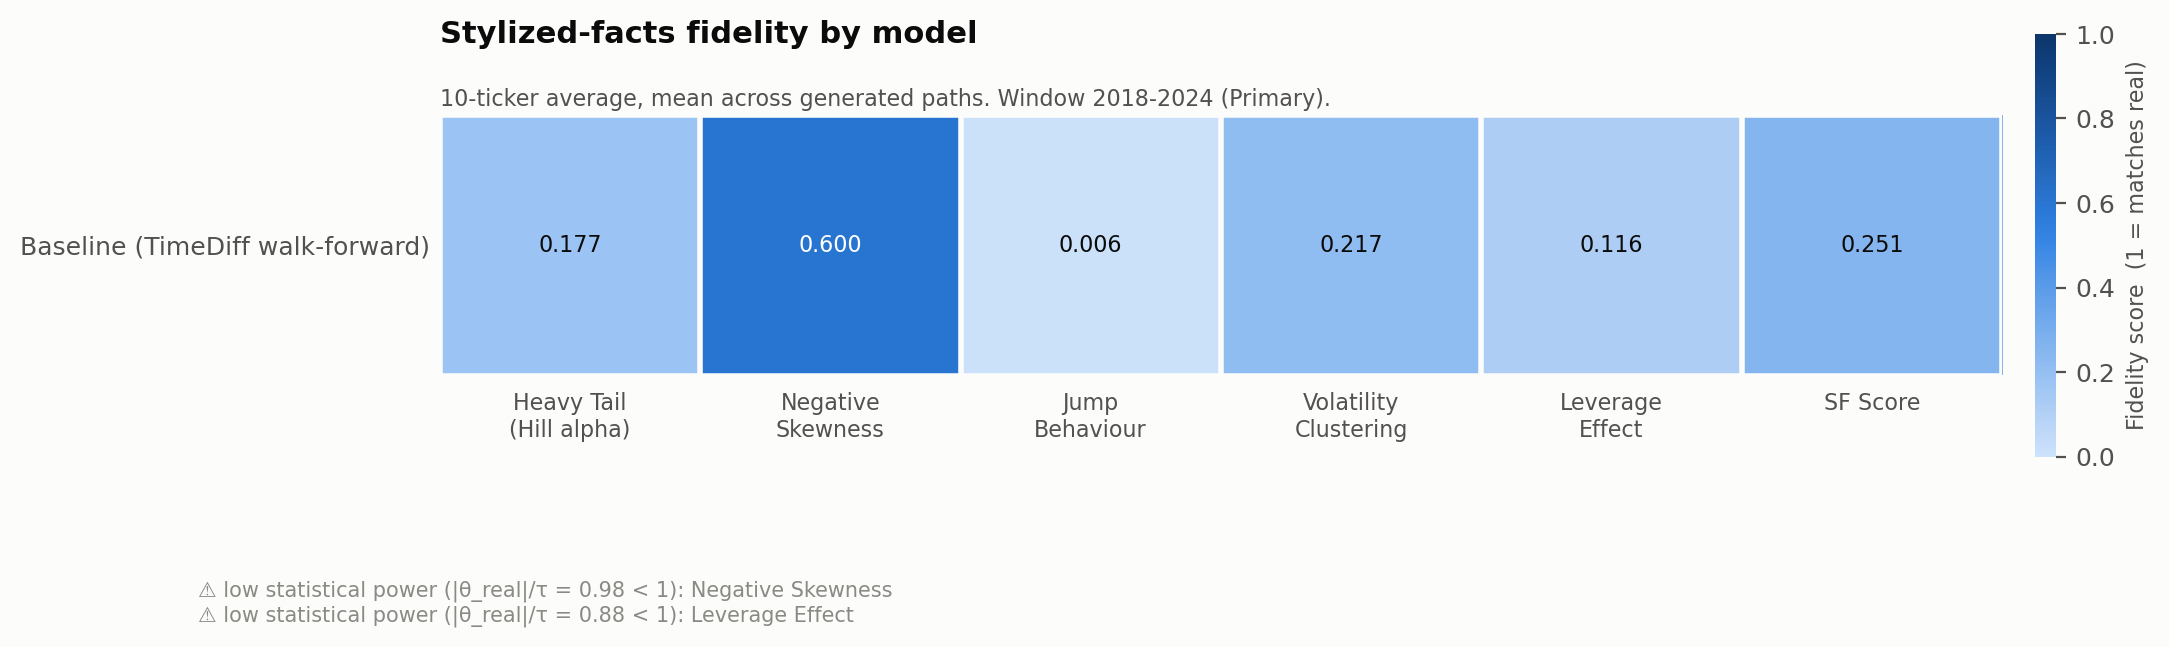

**cross_asset_scores**

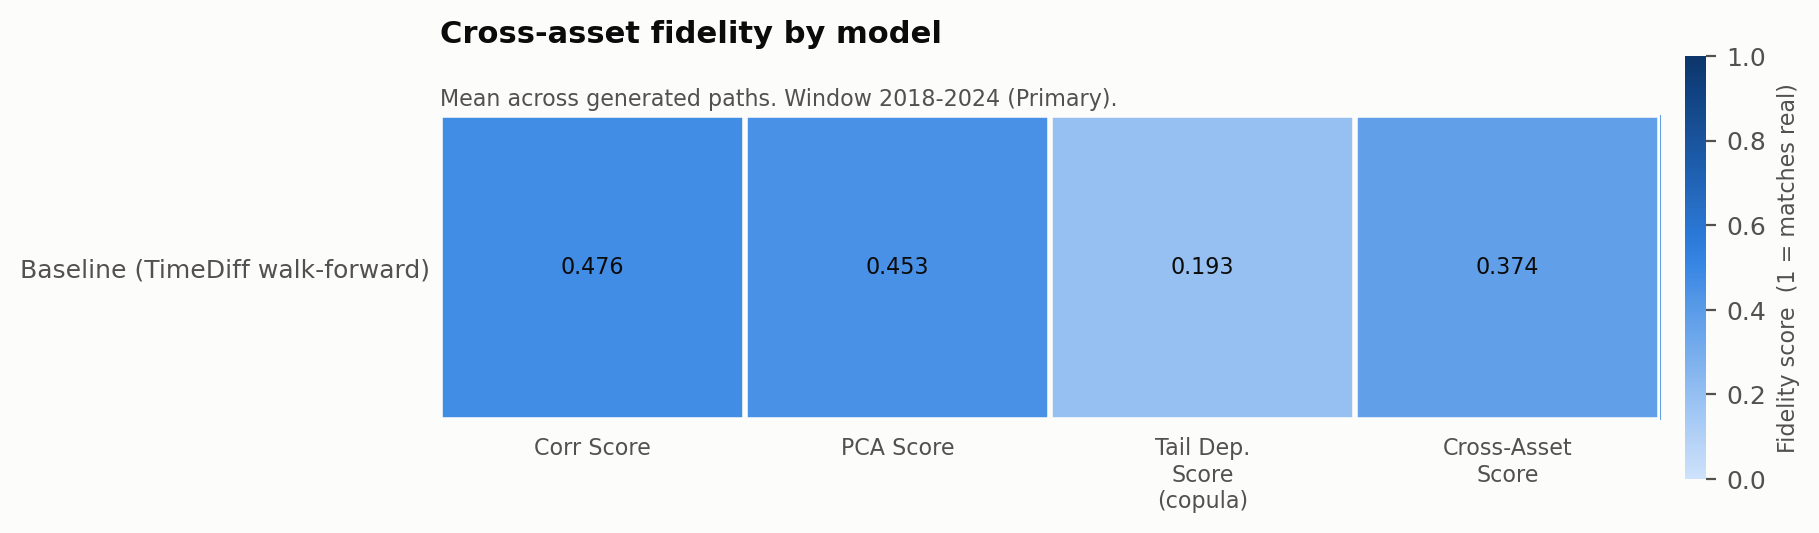

**pca_spectrum**

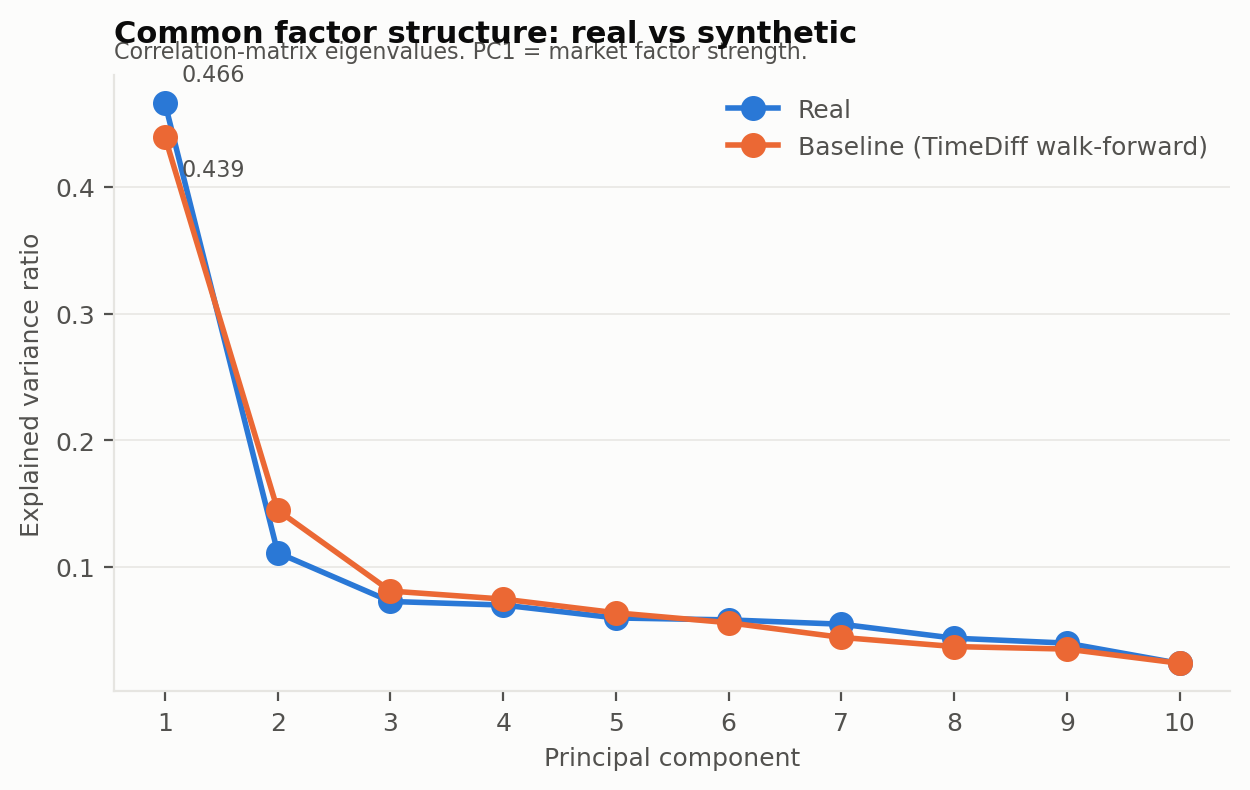

In [29]:
for n in ["stylized_scores", "cross_asset_scores", "pca_spectrum"]:
    display(Markdown(f"**{n}**")); display(Image(os.path.join(C.FIG_DIR, n + ".png")))

**asset_level_scores_Baseline**

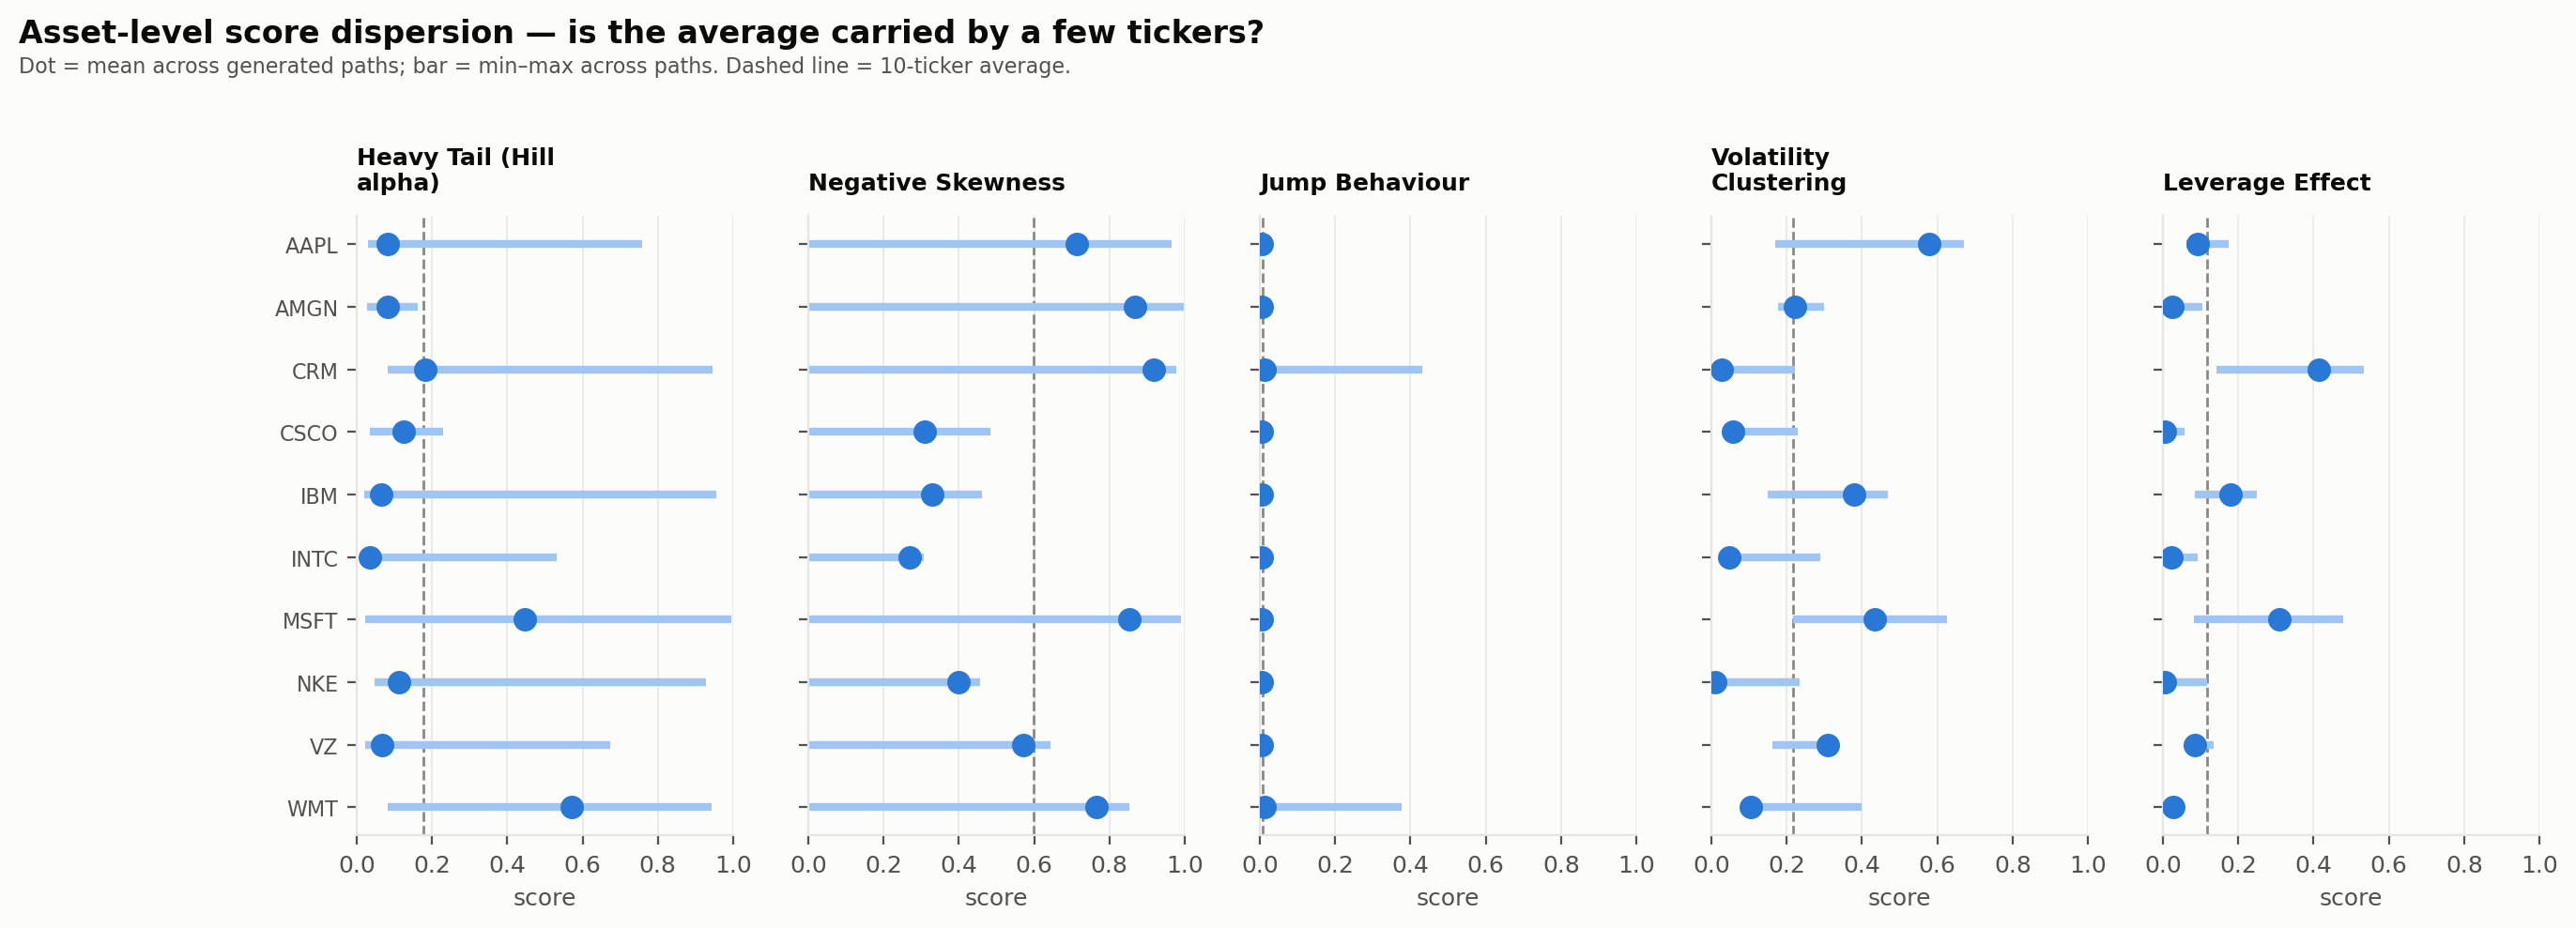

**correlation_matrix_Baseline**

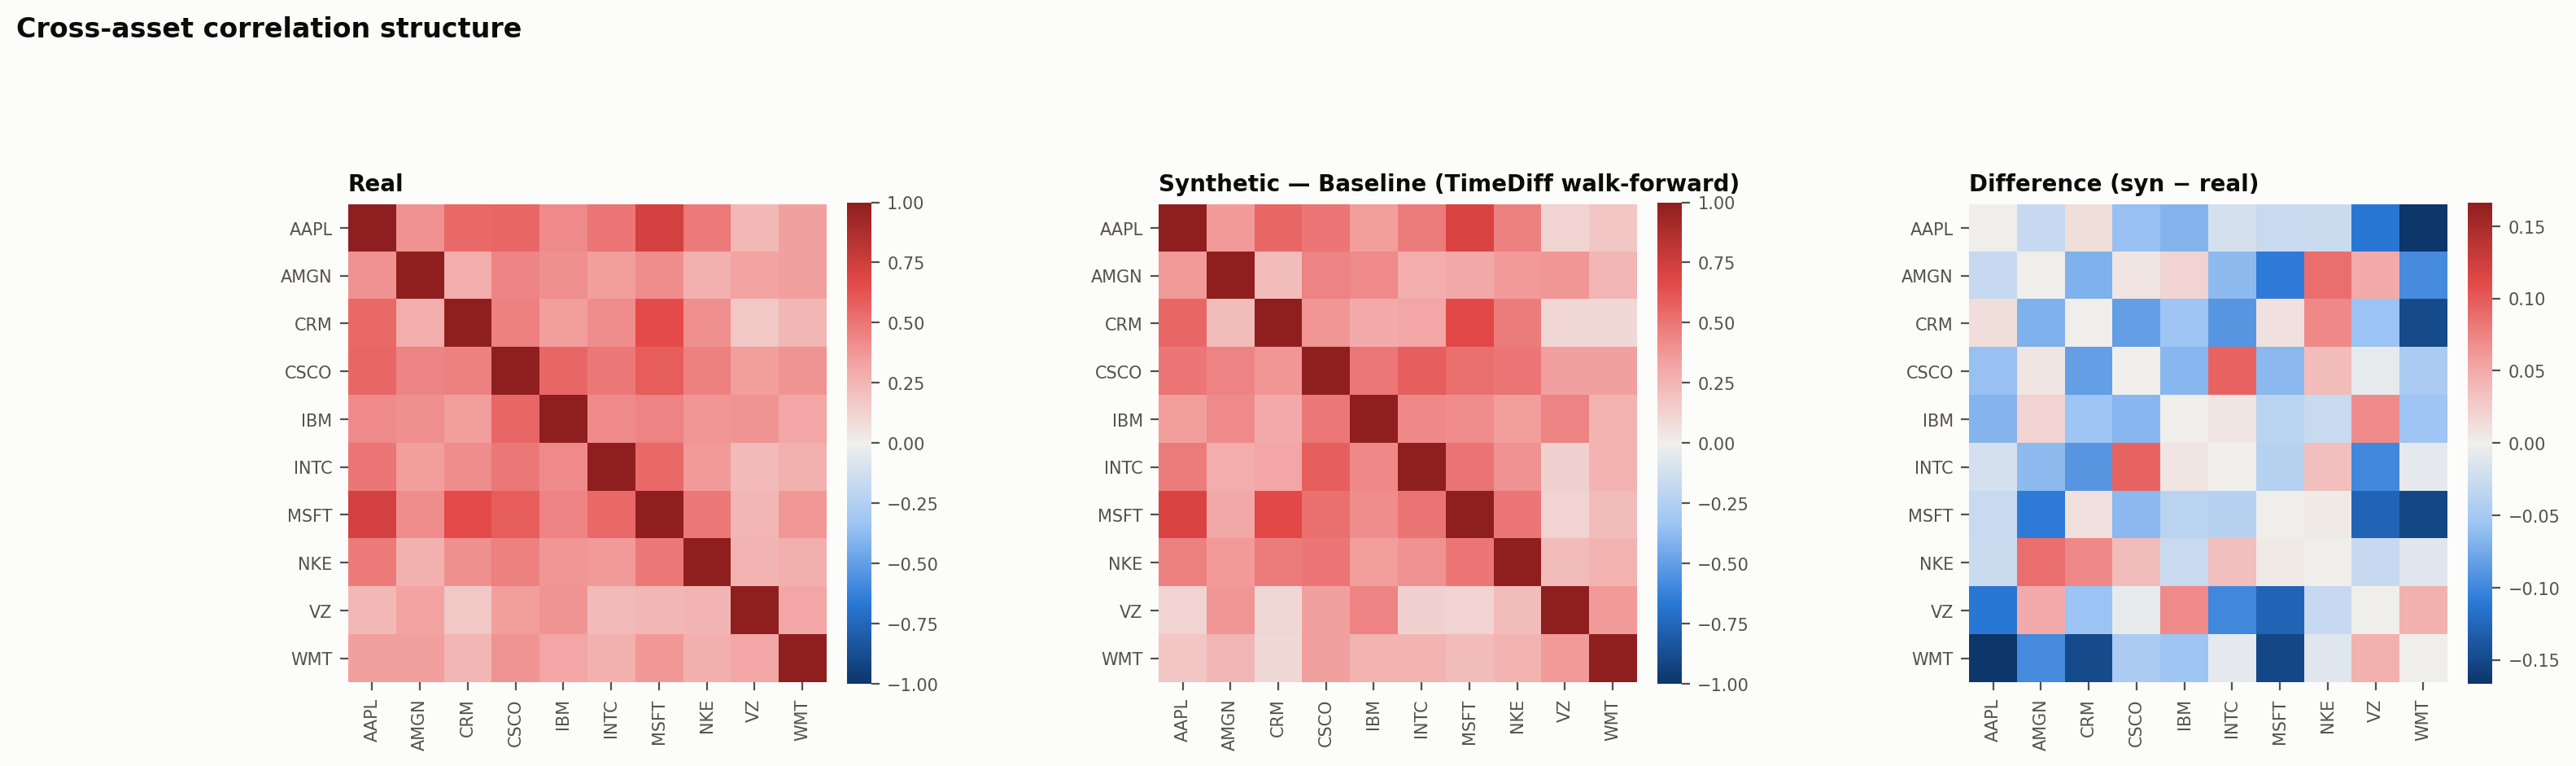

**overall_comparison**

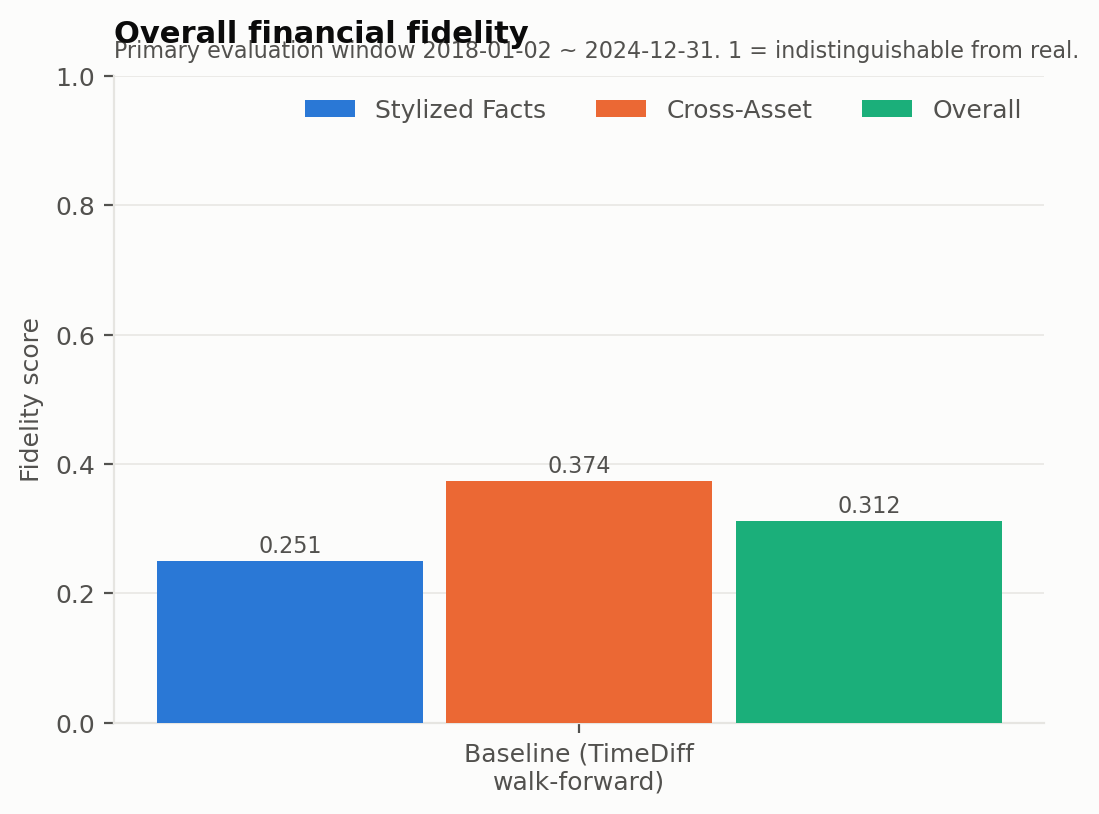

**tail_dependence_Baseline**

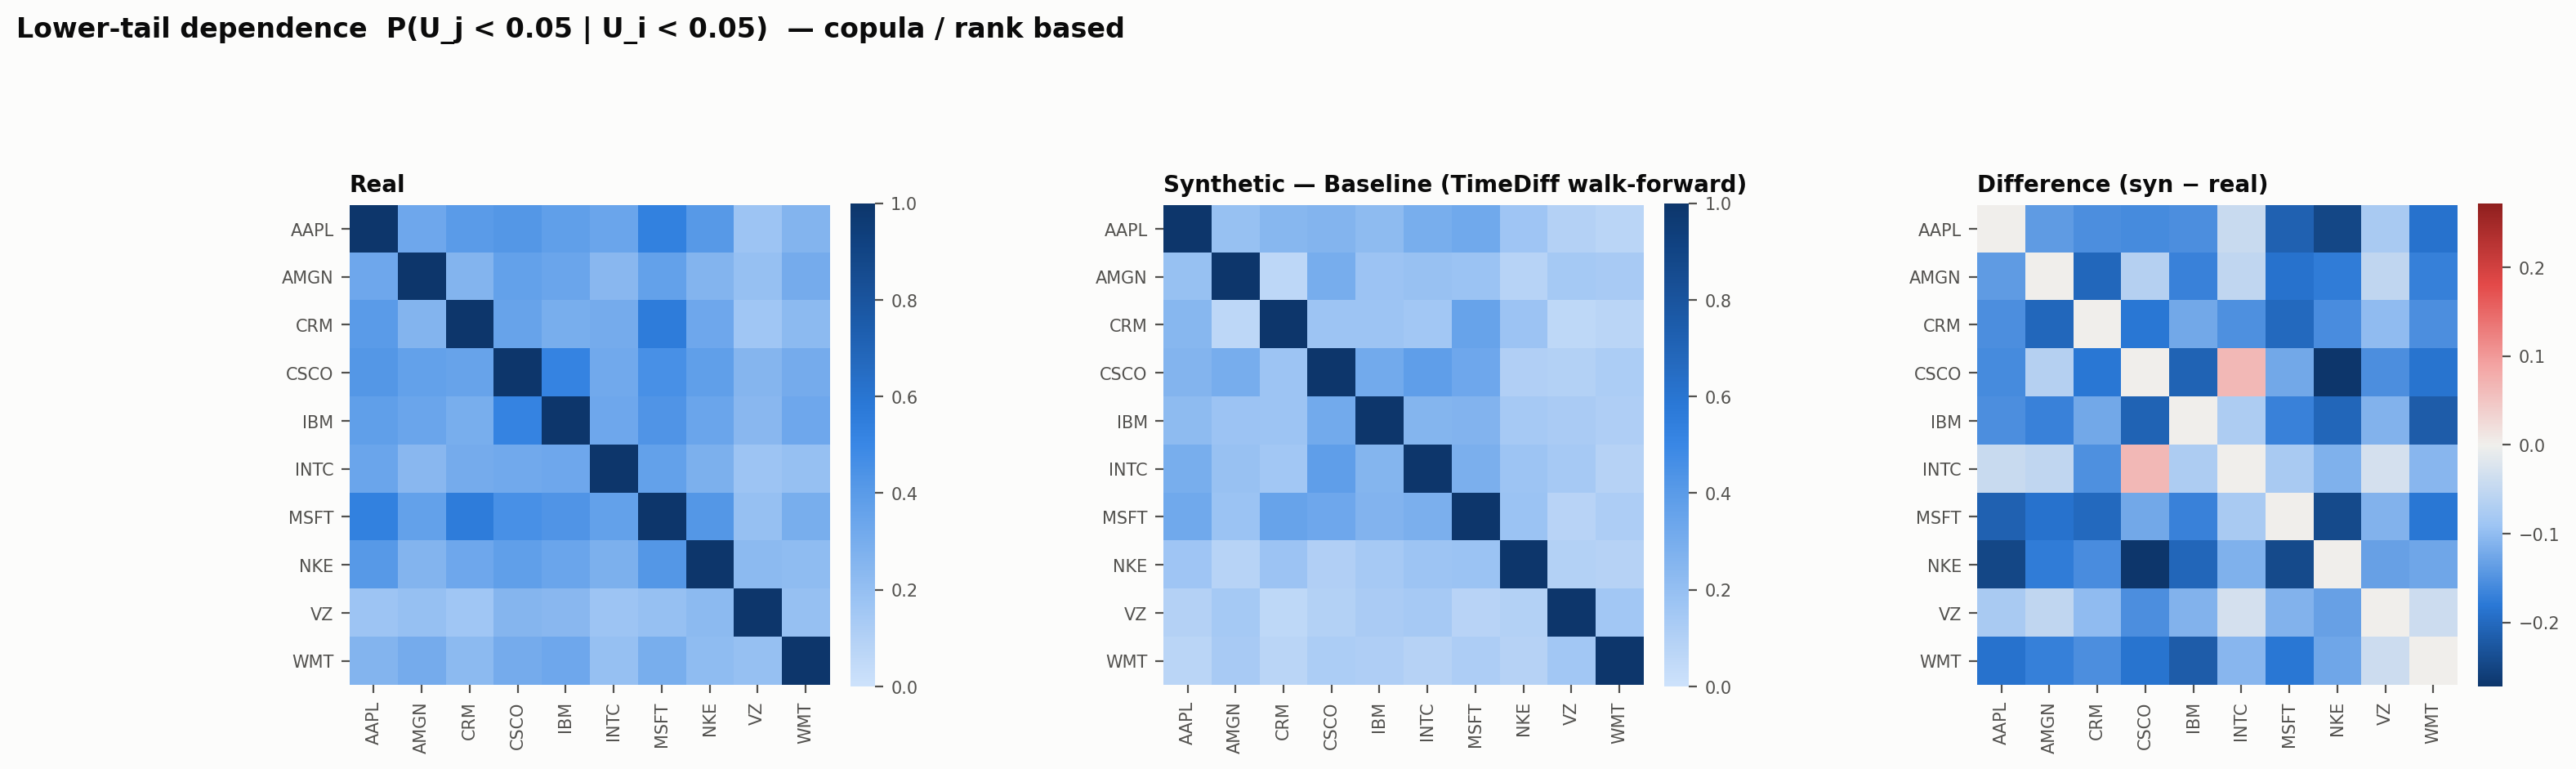

In [30]:
for f in sorted(os.listdir(C.FIG_DIR)):
    if f.startswith(("correlation_matrix", "tail_dependence", "overall_comparison", "asset_level")):
        display(Markdown(f"**{f[:-4]}**")); display(Image(os.path.join(C.FIG_DIR, f)))

---
## 20. Final Research Interpretation

產生兩份報告檔，並輸出結論。

In [31]:
p1 = RA.write_methodology_report(results, tau_cache)
p2 = RA.write_paper_summary(results)
print("已產生：")
print(" ", p1)
print(" ", p2)

已產生：
  /mnt/kartd0030027/TimeDiff/results/evaluation_methodology_report.txt
  /mnt/kartd0030027/TimeDiff/results/paper_results_summary.txt


In [32]:
print(open(p2).read())

PAPER RESULTS SUMMARY
Primary evaluation window: 2018-01-02 ~ 2024-12-31

[NOTE] 目前只有一個模型（baseline）進入主表，因此所有『最佳模型』欄位皆為該模型，
       排名與 trade-off 分析要等 fine-tuned 版本加入後才有意義。
       以下先報告 baseline 的絕對表現與強弱項。

1. BEST STYLIZED FACTS MODEL
----------------------------------------------------------------------------------------------------
   Baseline (TimeDiff walk-forward)   SF Score = 0.2507

2. BEST CROSS-ASSET MODEL
----------------------------------------------------------------------------------------------------
   Baseline (TimeDiff walk-forward)   Cross-Asset Score = 0.3740

3. BEST OVERALL MODEL
----------------------------------------------------------------------------------------------------
   Baseline (TimeDiff walk-forward)   Overall = 0.3124
   注意：排名不可只看 Overall Score，必須同時檢視第 9 節的 trade-off 分析。

4. STRONGEST STYLIZED FACT
----------------------------------------------------------------------------------------------------
   Baseline (TimeDiff walk-forward): Negative Skewness